**BẢNG RFM SUMMARY**

In [1]:
import os
import sys

# 1. Thêm thư mục gốc của project (root) vào sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

# 2. Import hàm từ file clustering (clustering.py) nằm trong thư mục src
from src.visualization import merge_and_report_kmeans_fast

# 3. Gọi hàm với đường dẫn tương đối tính từ vị trí thư mục notebooks
rfm_summary, business_summary, df_merged = merge_and_report_kmeans_fast(
    clustered_path="../data/processed/rfm_kmeans_clustered.csv",
    rfm_raw_path="../data/processed/rfm_raw.csv",
    olist_cleaned_path="../data/processed/olist_cleaned_dataset.csv",
    output_merged_csv="../data/processed/rfm_kmeans_merged_detail.csv",
    tables_report_dir="../reports/tables",
)

# 4. Hiển thị thử kết quả ngay trên notebook cell
display(rfm_summary)

⚡ Đã xử lý xong siêu tốc! Tổng: 93357 khách hàng (1-1) với chỉ số RFM thô.


,Recency,Frequency,Monetary,So_luong,Ty_le_%
Cluster,,,,,
0,171.469750,1.000000,309.990765,28826,30.88
1,426.287943,1.000000,121.855003,26856,28.77
2,220.294538,2.113888,308.588793,2801,3.00
3,149.246803,1.000000,67.378930,34874,37.36


**BẢNG BUSINESS SUMMARY**

In [2]:
# Hiển thị bảng tổng hợp chỉ số kinh doanh
print("\n--- BẢNG BUSINESS SUMMARY ---")
display(business_summary.head())


--- BẢNG BUSINESS SUMMARY ---


,Cluster,Recency,Frequency,Monetary,freight_value,review_score,customer_state,customer_city,category
0,0,171.47,1.00,309.99,33.54,4.04,SP,sao paulo,watches_gifts
1,1,426.29,1.00,121.86,20.00,4.22,SP,sao paulo,bed_bath_table
2,2,220.29,2.11,308.59,22.89,4.21,SP,sao paulo,bed_bath_table
3,3,149.25,1.00,67.38,16.01,4.19,SP,sao paulo,health_beauty


**BIỂU ĐỒ TRỰC QUAN**

🖼️ Đã lưu biểu đồ tại: ../reports/figures\rfm_overview.png


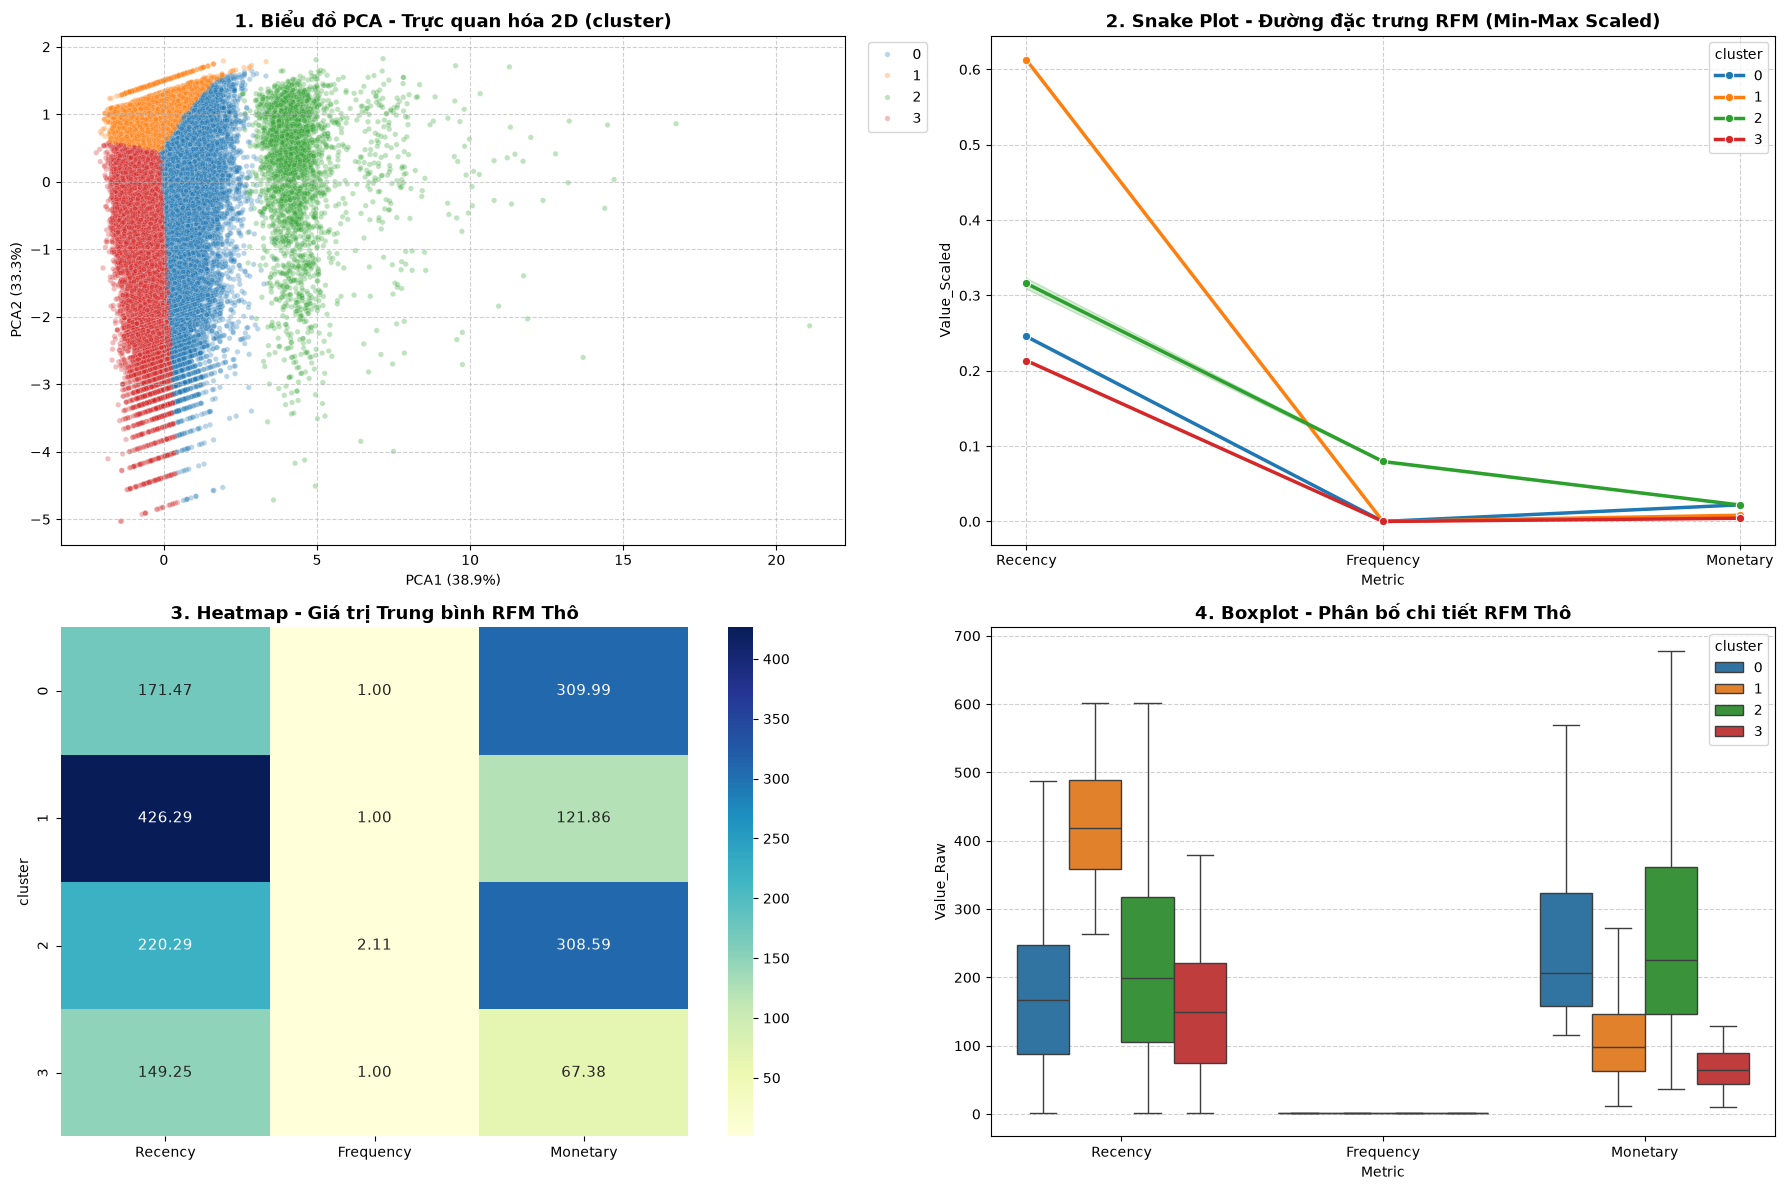

🖼️ Đã lưu biểu đồ tại: ../reports/figures\business_insights.png


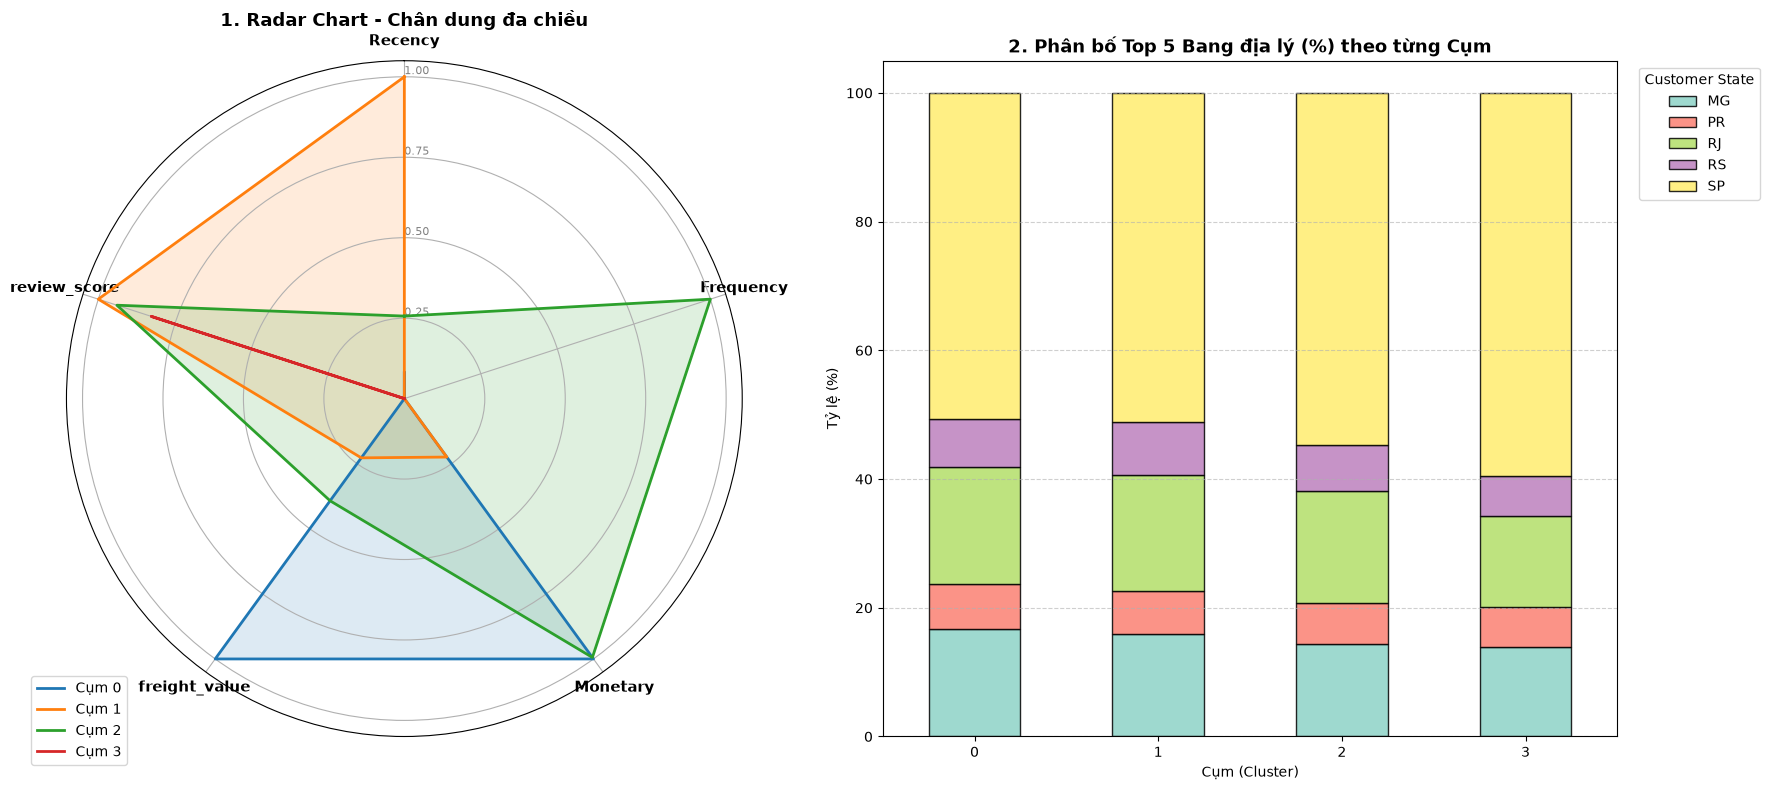

🖼️ Đã lưu biểu đồ tại: ../reports/figures\top_categories.png


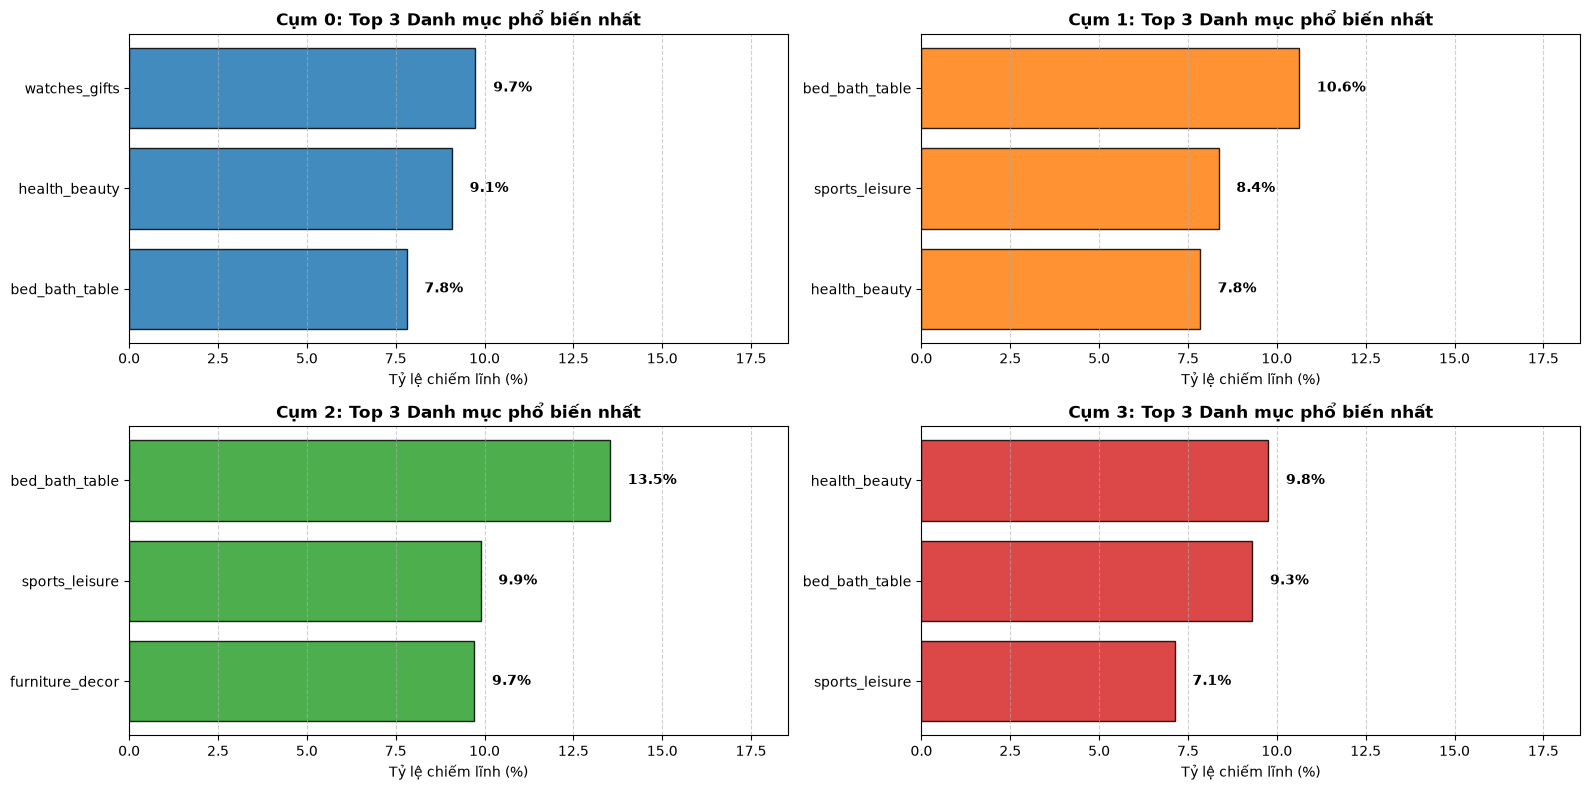

In [1]:
import sys
from pathlib import Path
import pandas as pd

# 1. Thêm thư mục gốc vào sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.visualization import ClusterVisualizer

# 2. Đọc dữ liệu
csv_path = project_root / 'data' / 'processed' / 'rfm_kmeans_merged_detail.csv'
df_merged = pd.read_csv(csv_path)

# 3. Chuyển tên cột 'Cluster' thành 'cluster' viết thường để khớp với code trong src
df_merged = df_merged.rename(columns={'Cluster': 'cluster'})

# 4. Khởi tạo visualizer với cluster_col='cluster'
viz = ClusterVisualizer(df_merged, cluster_col='cluster')

# 5. Chạy các biểu đồ
viz.plot_rfm_overview()

viz.plot_business_insights(
    freight_col='freight_value',
    review_col='review_score',
    state_col='customer_state',
)

viz.plot_top_categories(category_col='category', top_n=3)